In [1]:
!apt-get install ncbi-blast+ -y

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  ncbi-data
The following NEW packages will be installed:
  ncbi-blast+ ncbi-data
0 upgraded, 2 newly installed, 0 to remove and 35 not upgraded.
Need to get 15.8 MB of archives.
After this operation, 71.8 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu jammy/universe amd64 ncbi-data all 6.1.20170106+dfsg1-9 [3,519 kB]
Get:2 http://archive.ubuntu.com/ubuntu jammy/universe amd64 ncbi-blast+ amd64 2.12.0+ds-3build1 [12.3 MB]
Fetched 15.8 MB in 5s (3,141 kB/s)
Selecting previously unselected package ncbi-data.
(Reading database ... 126374 files and directories currently installed.)
Preparing to unpack .../ncbi-data_6.1.20170106+dfsg1-9_all.deb ...
Unpacking ncbi-data (6.1.20170106+dfsg1-9) ...
Selecting previously unselected package ncbi-blast+.
Preparing to unpack .../ncbi-blast+_2.12.0+ds-3build1_amd64.deb 

In [2]:
# 1. Install Biopython
!pip install biopython

# 2. Download Swiss-Prot FASTA
!wget ftp://ftp.ncbi.nlm.nih.gov/blast/db/FASTA/swissprot.gz

# 3. Unzip
!gunzip swissprot.gz


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 9.3 MB/s eta 0:00:00
--2025-09-05 11:44:08--  ftp://ftp.ncbi.nlm.nih.gov/blast/db/FASTA/swissprot.gz
           => ‘swissprot.gz’
Resolving ftp.ncbi.nlm.nih.gov (ftp.ncbi.nlm.nih.gov)... 130.14.250.11, 130.14.250.12, 130.14.250.13, ...
Connecting to ftp.ncbi.nlm.nih.gov (ftp.ncbi.nlm.nih.gov)|130.14.250.11|:21... connected.
Logging in as anonymous ... Logged in!
==> SYST ... done.    ==> PWD ... done.
==> TYPE I ... done.  ==> CWD (1) /blast/db/FASTA ... done.
==> SIZE swissprot.gz ... 143234298
==> PASV ... done.    ==> RETR swissprot.gz ... done.
Length: 143234298 (137M) (unauthoritative)

swissprot.gz        100%[===================>] 136.60M  25.0MB/s    in 6.9s    

2025-09-05 11:44:17 (19.8 MB/s) - ‘swissprot.gz’ saved [143234298]



In [19]:
from Bio import SeqIO
import re
import numpy as np
import matplotlib.pyplot as plt


In [20]:
sequences, labels = [], []

for record in SeqIO.parse("swissprot", "fasta"):
    seq = str(record.seq)
    header = record.description

    # Extract species name inside brackets
    species = re.search(r"\[(.*?)\]", header)
    if species:
        sequences.append(seq)
        labels.append(species.group(1))

print("Total sequences:", len(sequences))
print("Example sequence:", sequences[0])
print("Example label:", labels[0])


Total sequences: 482697
Example sequence: MASKEMFEDTVEERVINEEYKIWKKNTPFLYDLVMTHALQWPSLTVQWLPEVTKPEGKDYALHWLVLGTHTSDEQNHLVVARVHIPNDDAQFDASHCDSDKGEFGGFGSVTGKIECEIKINHEGEVNRARYMPQNPHIIATKTPSSGVLVFDYTKHPAKPDPSGECNPDLRLRGHQKEGYGLSWNSNLSGHLLSASDDHTVCLWDINAGPKEGKIVDAKAVFTGHSAVVEDVAWHLLHESLFGSVADDQKLMMWDTRSNTTSKPSHLVDAHTAEVNCLSFNPYSEFILATGSADKTVALWDLRNLKLKLHTFESHKDEIFQVVHWSPHNETILASSGTDRRLNVWDLSKIGEEQSAEDAEDGPPELLFIHGGHTAKISDFSWNPNEPWVICSVSEDNIMQIWQMAENIYNDEESDVTTSELEGQGS
Example label: Pongo abelii


In [21]:
AMINO_ACIDS = "ACDEFGHIKLMNPQRSTVWY"
aa_to_int = {aa: i for i, aa in enumerate(AMINO_ACIDS)}

def one_hot_encode(seq, max_len=1000):
    mat = np.zeros((max_len, len(AMINO_ACIDS)))
    for i, aa in enumerate(seq[:max_len]):  # truncate long sequences
        if aa in aa_to_int:
            mat[i, aa_to_int[aa]] = 1
    return mat


In [22]:
print(one_hot_encode(sequences[0]).shape)

(1000, 20)


0 - 100: 42777 sequences
100 - 200: 95176 sequences
200 - 300: 93719 sequences
300 - 400: 86037 sequences
400 - 500: 61077 sequences
500 - 600: 34997 sequences
600 - 700: 20965 sequences
700 - 800: 12963 sequences
800 - 900: 9653 sequences
900 - 1000: 6832 sequences
1000 - 1100: 4045 sequences
1100 - 1200: 2838 sequences
1200 - 1300: 2151 sequences
1300 - 1400: 1953 sequences
1400 - 1500: 1623 sequences
1500 - 1600: 850 sequences
1600 - 1700: 646 sequences
1700 - 1800: 592 sequences
1800 - 1900: 504 sequences
1900 - 2000: 394 sequences
2000 - 2100: 273 sequences
2100 - 2200: 385 sequences
2200 - 2300: 339 sequences
2300 - 2400: 237 sequences
2400 - 2500: 200 sequences
2500 - 2600: 171 sequences
2600 - 2700: 106 sequences
2700 - 2800: 99 sequences
2800 - 2900: 79 sequences
2900 - 3000: 54 sequences
3000 - 3100: 116 sequences
3100 - 3200: 78 sequences
3200 - 3300: 34 sequences
3300 - 3400: 62 sequences
3400 - 3500: 79 sequences
3500 - 3600: 35 sequences
3600 - 3700: 34 sequences
3700 - 3

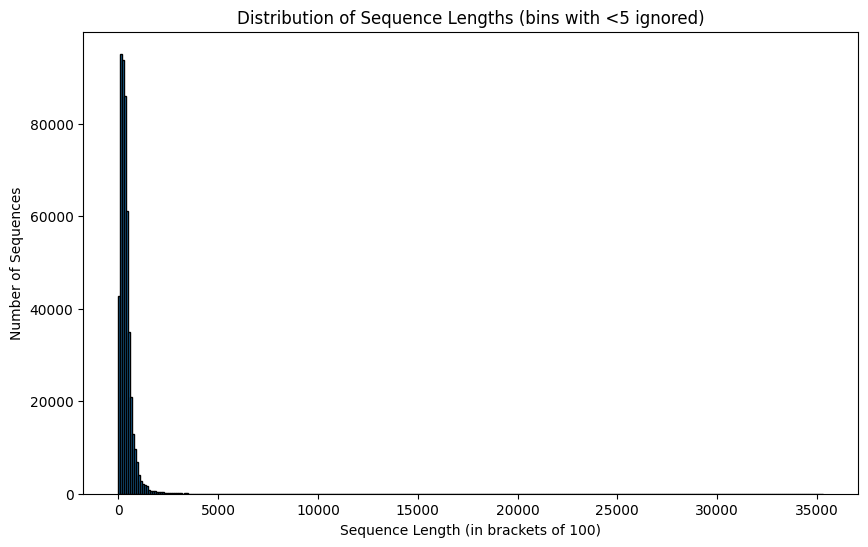

In [23]:
# Load lengths
lengths = [len(record.seq) for record in SeqIO.parse("swissprot", "fasta")]

# Bin into brackets of 100
bins = np.arange(0, max(lengths) + 100, 100)
hist, bin_edges = np.histogram(lengths, bins=bins)

# Print counts per bracket (ignoring bins with <5 sequences)
for i in range(len(hist)):
    if hist[i] >= 5:
        print(f"{bin_edges[i]} - {bin_edges[i+1]}: {hist[i]} sequences")

# Filter out bins with <5 sequences for plotting
filtered_lengths = [l for l in lengths if sum((l >= bin_edges[i]) and (l < bin_edges[i+1]) for i in range(len(hist)) if hist[i] >= 5)]

# Plot histogram with same binning, only showing bins with >=5
plt.figure(figsize=(10,6))
plt.hist(filtered_lengths, bins=bins, edgecolor='black')
plt.xlabel("Sequence Length (in brackets of 100)")
plt.ylabel("Number of Sequences")
plt.title("Distribution of Sequence Lengths (bins with <5 ignored)")
plt.show()
